# Notebook 15 — FastAPI Recommendation Serving (MVP First)

**Scope:** Windows Conda `torch`; local single-worker HTTP service; real LightGBM + DeepFM inference; frozen MMR λ=0.9; cached Notebook08 retrieval and Notebook09 features. Compare Top-20 against Notebook13. Measure HTTP P50/P95/P99 and sequential QPS. **Not** live retrieval, online feature engineering, production QPS, CTR, or CVR.

**Files:** Copy `notebook15_service.py` to project root, `notebook15_requirements.txt` to project root, and this notebook into `notebooks/`. Notebook starts a local Uvicorn subprocess and shuts it down in the final cell. Use only local trusted artifacts.

## 0. Setup and dependencies

Run `python -m pip install -r notebook15_requirements.txt` in the **same Conda torch environment** if FastAPI/Uvicorn/httpx are missing. Preserve your existing CUDA PyTorch installation.

In [3]:
from pathlib import Path
import os,sys,time,json,subprocess,platform,random,socket,contextlib
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import httpx
from IPython.display import display
SEED=42
np.random.seed(SEED);random.seed(SEED)
ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
assert ROOT is not None,'Open notebook from project root or notebooks/; missing notebook02.duckdb'
assert (ROOT/'notebook15_service.py').is_file(),'Copy notebook15_service.py into the project root'
OUT=ROOT/'data'/'processed';REPORT=ROOT/'data'/'reports';PLOTS=REPORT/'notebook15_plots'
REPORT.mkdir(exist_ok=True,parents=True);PLOTS.mkdir(exist_ok=True,parents=True)
SPLIT='test';N_REQUESTS=60;WARMUP=5;TOP_K=20;PORT=8015
BASE=f'http://127.0.0.1:{PORT}'
print('Python:',sys.executable,'Root:',ROOT,'Base:',BASE)


Python: c:\Users\wyr95\.conda\envs\torch\python.exe Root: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks Base: http://127.0.0.1:8015


## 1. Start local service (single worker)

Models and feature caches load **once** in the server lifespan. This startup time is reported separately and excluded from warm HTTP latency. Server must not be publicly exposed.

In [4]:
# Stop a previously started server process from this notebook kernel, if present.
if 'server' in globals() and server is not None and server.poll() is None:
    server.terminate();server.wait(timeout=15)
with socket.socket() as sock:
    assert sock.connect_ex(('127.0.0.1',PORT))!=0,f'Port {PORT} occupied. Stop old server or change PORT.'
server_log=REPORT/'notebook15_server.log'
server_log_handle=open(server_log,'w',encoding='utf-8')
env=os.environ.copy();env['NOTEBOOK15_PROJECT_ROOT']=str(ROOT);env['NOTEBOOK15_SPLIT']=SPLIT
cmd=[sys.executable,'-m','uvicorn','notebook15_service:app','--host','127.0.0.1','--port',str(PORT),'--workers','1','--no-access-log']
startup_begin=time.perf_counter()
server=subprocess.Popen(cmd,cwd=str(ROOT),env=env,stdout=server_log_handle,stderr=subprocess.STDOUT)
client=httpx.Client(base_url=BASE,timeout=120.0,trust_env=False)
health=None
for attempt in range(120):
    if server.poll() is not None:break
    try:
        r=client.get('/health',timeout=2)
        if r.status_code==200:health=r.json();break
    except (httpx.HTTPError,OSError):pass
    time.sleep(.5)
startup_seconds=time.perf_counter()-startup_begin
if health is None:
    server_log_handle.flush()
    raise RuntimeError('Server failed to start; inspect '+str(server_log)+' | '+server_log.read_text(encoding='utf-8',errors='replace')[-2500:])
print('Health:',health,'Startup seconds:',round(startup_seconds,2))
assert health['real_model_inference'] and health['mmr_lambda']==.9


Health: {'status': 'ok', 'device': 'cuda', 'users_cached': 3572, 'mmr_lambda': 0.9, 'retrieval': 'precomputed', 'features': 'precomputed', 'real_model_inference': True} Startup seconds: 15.13


## 2. Validate API and freeze deterministic request sample

Use test data only for implementation audit and frozen timing. Do **not** select models or λ based on test metrics.

In [5]:
mmr_path=OUT/f'{SPLIT}_mmr_top500.parquet'
assert mmr_path.exists()
ref=pd.read_parquet(mmr_path,columns=['user_id','item_id','mmr_rank'])
reference={int(uid):g.sort_values('mmr_rank').item_id.to_numpy(dtype=np.int64) for uid,g in ref.groupby('user_id',sort=False)}
users=np.asarray(sorted(reference),dtype=np.int64)
selected=np.random.default_rng(SEED).choice(users,size=min(N_REQUESTS,len(users)),replace=False)
warm=selected[:WARMUP];timed=selected[WARMUP:]
assert len(timed)>0
uid=int(selected[0]);r=client.get('/recommend',params={'user_id':uid,'k':TOP_K});r.raise_for_status()
print('Example response:',r.json())
assert r.json()['candidate_count']==500
assert r.json()['items']==reference[uid][:TOP_K].tolist(),'Top-20 parity failed'
print('Selected:',len(selected),'Warmup:',len(warm),'Timed:',len(timed))


Example response: {'user_id': 1059345, 'k': 20, 'candidate_count': 500, 'mmr_lambda': 0.9, 'items': [111201, 360922, 138427, 227215, 265810, 342330, 49466, 368488, 290993, 46156, 123664, 283896, 27897, 126236, 141295, 282436, 196659, 373725, 203627, 413990], 'stage_ms': {'lgbm_preprocess': 8.8659, 'lgbm_inference': 4.364, 'deepfm_preprocess': 7.5946, 'deepfm_inference': 290.0247, 'mmr_greedy': 3.6966}, 'total_ms': 314.5575}
Selected: 60 Warmup: 5 Timed: 55


## 3. Request validation and health checks

Check malformed `k`, unknown user, and health status. `/reference` is a local debugging endpoint and must not be exposed in a production deployment.

In [6]:
checks=[]
for label,path,params,expected in [
    ('health','/health',{},200),
    ('missing_user_id','/recommend',{},422),
    ('invalid_k_zero','/recommend',{'user_id':uid,'k':0},422),
    ('invalid_k_over_100','/recommend',{'user_id':uid,'k':101},422),
    ('unknown_user','/recommend',{'user_id':999999999999,'k':20},404),
]:
    rr=client.get(path,params=params)
    checks.append({'check':label,'status':rr.status_code,'expected':expected,'passed':rr.status_code==expected})
CHECKS=pd.DataFrame(checks);display(CHECKS)
assert CHECKS.passed.all()


,check,status,expected,passed
0,health,200,200,True
1,missing_user_id,422,422,True
2,invalid_k_zero,422,422,True
3,invalid_k_over_100,422,422,True
4,unknown_user,404,404,True


## 4. HTTP benchmark: real model inference + serialization + loopback network

Single client, sequential requests. P50/P95/P99 are sample percentiles, **not production SLOs**. HTTP total latency includes server processing, serialization, and loopback transport; response `total_ms` measures server-side inference path only. Models, cached retrieval and features remain warm.

In [7]:
for u in warm:
    rr=client.get('/recommend',params={'user_id':int(u),'k':TOP_K});rr.raise_for_status()
rows=[];audits=[];stage_rows=[]
for j,u in enumerate(timed):
    u=int(u)
    start=time.perf_counter()
    rr=client.get('/recommend',params={'user_id':u,'k':TOP_K})
    http_ms=(time.perf_counter()-start)*1000
    rr.raise_for_status();payload=rr.json()
    expected=reference[u][:TOP_K].tolist();actual=payload['items']
    exact=actual==expected
    rows.append({'request_index':j,'user_id':u,'http_ms':http_ms,'server_ms':payload['total_ms'],
                 'transport_and_serialization_overhead_ms':http_ms-payload['total_ms'],
                 'candidate_count':payload['candidate_count'],'exact_top20':exact})
    audits.append({'user_id':u,'exact_top20':exact,'overlap_at_20':len(set(actual)&set(expected))/TOP_K,
                   'candidate_count':payload['candidate_count'],'returned_count':len(actual)})
    for stage,ms in payload['stage_ms'].items():stage_rows.append({'user_id':u,'stage':stage,'latency_ms':ms})
    if (j+1)%10==0:print('Completed:',j+1,'/',len(timed))
REQUESTS=pd.DataFrame(rows);AUDIT=pd.DataFrame(audits);STAGES=pd.DataFrame(stage_rows)
assert AUDIT.exact_top20.all(),'Serving parity failed: investigate before trusting benchmark'
assert (AUDIT.candidate_count==500).all() and (AUDIT.returned_count==20).all()
print('Top-20 parity:',AUDIT.exact_top20.mean())


Completed: 10 / 55
Completed: 20 / 55
Completed: 30 / 55
Completed: 40 / 55
Completed: 50 / 55
Top-20 parity: 1.0


## 5. Metrics, reports, and charts

,mode,n,mean_ms,p50_ms,p95_ms,p99_ms,max_ms,sequential_qps,sequential_qps_equivalent
0,http_loopback,55,23.523102,22.9478,27.76319,35.218978,36.3229,42.5114,NaN
1,server_inference,55,20.586016,19.8357,24.09848,30.715150,32.1205,NaN,48.576664


,stage,n,mean_ms,p50_ms,p95_ms,p99_ms,max_ms
1,deepfm_preprocess,55,6.048205,6.0609,6.82902,8.476546,8.5765
3,lgbm_preprocess,55,4.810631,4.5577,6.89097,7.625444,8.2472
4,mmr_greedy,55,4.101996,3.8704,5.88035,6.631638,6.7263
2,lgbm_inference,55,2.880564,2.6780,3.74340,5.202012,5.2950
0,deepfm_inference,55,2.738100,2.4396,4.52555,4.982182,5.0803


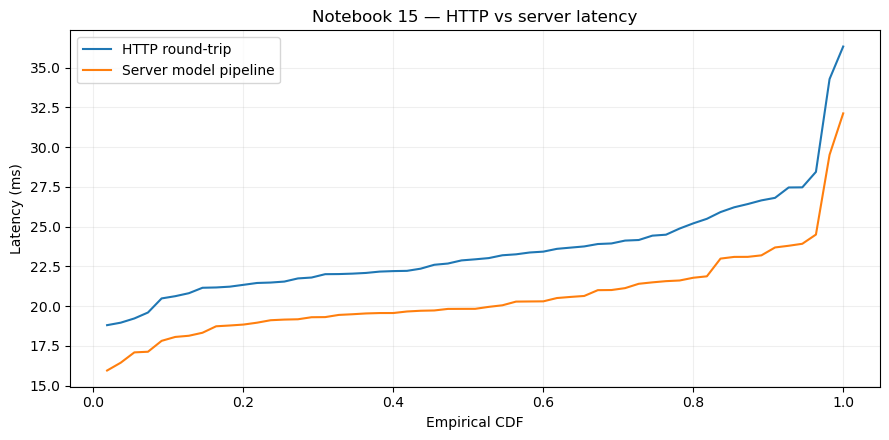

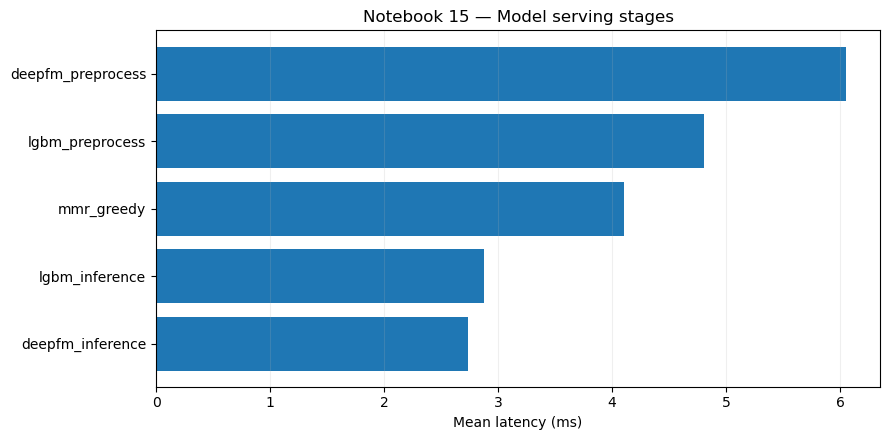

In [8]:
def stats(values):
    v=np.asarray(values,dtype=float)
    return {'n':len(v),'mean_ms':float(v.mean()),'p50_ms':float(np.percentile(v,50)),
            'p95_ms':float(np.percentile(v,95)),'p99_ms':float(np.percentile(v,99)),
            'max_ms':float(v.max())}
HTTP=stats(REQUESTS.http_ms);SERVER=stats(REQUESTS.server_ms)
# QPS based on sum of sequential request wall times, excluding startup/warmup.
HTTP['sequential_qps']=float(1000*len(REQUESTS)/REQUESTS.http_ms.sum())
SERVER['sequential_qps_equivalent']=float(1000*len(REQUESTS)/REQUESTS.server_ms.sum())
STAGE_METRICS=pd.DataFrame([{'stage':stage,**stats(g.latency_ms)} for stage,g in STAGES.groupby('stage')])
display(pd.DataFrame([{'mode':'http_loopback',**HTTP},{'mode':'server_inference',**SERVER}]))
display(STAGE_METRICS.sort_values('mean_ms',ascending=False))
REQUESTS.to_csv(REPORT/'notebook15_http_request_samples.csv',index=False)
AUDIT.to_csv(REPORT/'notebook15_serving_parity_audit.csv',index=False)
STAGES.to_csv(REPORT/'notebook15_stage_samples.csv',index=False)
STAGE_METRICS.to_csv(REPORT/'notebook15_stage_latency.csv',index=False)
CHECKS.to_csv(REPORT/'notebook15_endpoint_checks.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4.5))
for col,label in [('http_ms','HTTP round-trip'),('server_ms','Server model pipeline')]:
    values=np.sort(REQUESTS[col].to_numpy());ax.plot(np.arange(1,len(values)+1)/len(values),values,label=label)
ax.set(xlabel='Empirical CDF',ylabel='Latency (ms)',title='Notebook 15 — HTTP vs server latency');ax.grid(alpha=.2);ax.legend()
fig.tight_layout();fig.savefig(PLOTS/'notebook15_http_latency_cdf.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(9,4.5))
ss=STAGE_METRICS.sort_values('mean_ms');ax.barh(ss.stage,ss.mean_ms)
ax.set(xlabel='Mean latency (ms)',title='Notebook 15 — Model serving stages');ax.grid(axis='x',alpha=.2)
fig.tight_layout();fig.savefig(PLOTS/'notebook15_stage_latency.png',dpi=160);plt.show()


## 6. Save reproducibility report and stop local server

In [9]:
report={
 'notebook':'15_fastapi_recommendation_serving','seed':SEED,'split':SPLIT,
 'environment':{'python':sys.version.split()[0],'platform':platform.platform(),
                'executable':sys.executable},
 'architecture':{'retrieval':'precomputed Notebook08 Top-500','features':'precomputed Notebook09',
                 'lightgbm':'actual model inference','deepfm':'actual model inference',
                 'mmr_lambda':health['mmr_lambda'],'mmr_pool':150,'mmr_depth':100,
                 'service':'FastAPI Uvicorn single worker localhost'},
 'health':health,'startup_seconds_excluded':startup_seconds,
 'requests':{'total':len(selected),'warmup':len(warm),'timed':len(timed),'sequential':True},
 'http_latency':HTTP,'server_latency':SERVER,
 'stage_latency':STAGE_METRICS.to_dict(orient='records'),
 'audit':{'top20_exact_rate':float(AUDIT.exact_top20.mean()),
          'min_candidate_count':int(AUDIT.candidate_count.min()),
          'max_candidate_count':int(AUDIT.candidate_count.max()),
          'endpoint_validation_passed':bool(CHECKS.passed.all())},
 'outputs':['notebook15_http_request_samples.csv','notebook15_serving_parity_audit.csv',
            'notebook15_stage_samples.csv','notebook15_stage_latency.csv','notebook15_endpoint_checks.csv',
            'notebook15_plots/notebook15_http_latency_cdf.png','notebook15_plots/notebook15_stage_latency.png'],
 'limitations':['No live retrieval or raw-event feature generation','All candidates/features precomputed and held in memory',
                'LightGBM scores computed but not used for candidate pruning; both models score all 500',
                'Single-process sequential loopback HTTP; not concurrent production load',
                'Only 55 timed requests by default; percentiles noisy',
                'Test used for frozen parity and timing, not model selection',
                'No impression logs, online CTR/CVR, autoscaling, authentication, or deployment claims']
}
report_path=REPORT/'notebook15_serving_report.json'
report_path.write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
print('Saved:',report_path)
# Gracefully close client and stop subprocess; repeatable Run All.
client.close()
if server.poll() is None:
    server.terminate()
    try:server.wait(timeout=15)
    except subprocess.TimeoutExpired:server.kill();server.wait(timeout=5)
server_log_handle.close()
print('Stopped server. Final HTTP P50/P95/P99 (ms):',*[round(HTTP[k],2) for k in ('p50_ms','p95_ms','p99_ms')])


Saved: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook15_serving_report.json
Stopped server. Final HTTP P50/P95/P99 (ms): 22.95 27.76 35.22


## Interpretation and next steps

- Confirm `top20_exact_rate == 1.0`; if not, **do not** trust benchmark. Review LightGBM categorical levels, DeepFM numeric transforms, and MMR tie-breaking.
- Compare Notebook 14 model replay P50 ≈ 24.57 ms against this notebook's **server** and **HTTP** results, but note different caching and preprocessing implementations.
- `notebook15_service.py` includes a local `/reference/{user_id}` audit endpoint. Disable it and add authentication, bounded caching, concurrency and observability before any public deployment.
- For genuine cascaded ranking, implement LightGBM candidate pruning to Top-100 and retrain/evaluate DeepFM and MMR on that distribution, using Validation for decisions. Current service deliberately preserves Notebook13 parity by scoring all 500.
- For production-like performance, benchmark more requests, cold starts, concurrency, memory footprint, and service under realistic data access.
